<a href="https://colab.research.google.com/github/jyothika-sasi/BEACON-PROJECT/blob/main/Beacon_XGboost_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install xgboost

In [ ]:
import pandas as pd
import numpy as np

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv(
    "/content/educational_datasets.csv"
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (2000, 13)

Column names:
['Student_ID', 'Age', 'CGPA', 'Attendance_Rate', 'Assignment_Avg', 'Internal_Mark', 'Backlogs', 'LMS_Login_Frequency', 'Video_Engagement_Time', 'Forum_Interactions', 'Engagement_Score', 'Stress_Level_Index', 'Dropout_Risk']


,Student_ID,Age,CGPA,Attendance_Rate,Assignment_Avg,Internal_Mark,Backlogs,LMS_Login_Frequency,Video_Engagement_Time,Forum_Interactions,Engagement_Score,Stress_Level_Index,Dropout_Risk
0,STD00001,23,5.60,93.16,44.70,71.37,2,9,6.18,13,0.63,0.68,0
1,STD00002,20,7.88,91.12,74.41,35.94,20,21,13.62,2,0.81,0.36,0
2,STD00003,24,7.00,58.67,45.90,40.26,17,9,8.62,17,0.81,0.86,0
3,STD00004,21,5.60,74.29,66.96,72.52,11,23,7.03,5,0.69,0.54,0
4,STD00005,23,4.90,55.85,96.43,95.86,11,9,9.88,16,0.83,0.55,0


In [ ]:
feature_columns = [
    "Age",
    "CGPA",
    "Attendance_Rate",
    "Assignment_Avg",
    "Internal_Mark",
    "Backlogs"
]

X = df[feature_columns]
y = df["Dropout_Risk"]

print("Selected features:")
print(X.columns.tolist())

print("Number of features:", X.shape[1])

Selected features:
['Age', 'CGPA', 'Attendance_Rate', 'Assignment_Avg', 'Internal_Mark', 'Backlogs']
Number of features: 6


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1600
Testing records: 400


In [ ]:
from xgboost import XGBClassifier

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    scale_pos_weight=negative_count / positive_count,
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


Accuracy: 0.9

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95       383
           1       0.29      0.94      0.44        17

    accuracy                           0.90       400
   macro avg       0.64      0.92      0.69       400
weighted avg       0.97      0.90      0.92       400


Confusion Matrix:
[[344  39]
 [  1  16]]


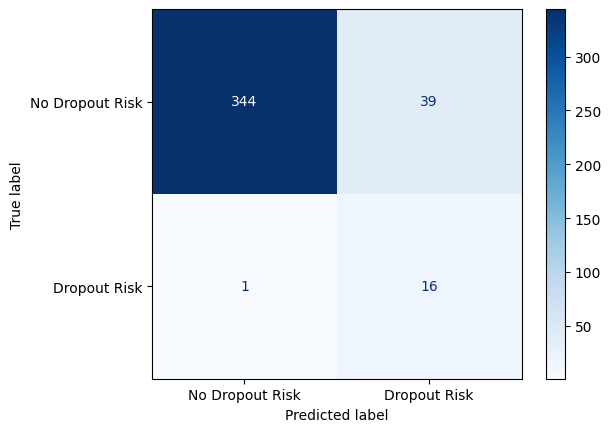

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Dropout Risk", "Dropout Risk"],
    cmap="Blues"
)

plt.show()

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nDropout risk counts:")
print(df["Dropout_Risk"].value_counts())

print("\nBacklog range:")
print(df["Backlogs"].min(), "to", df["Backlogs"].max())

Missing values:
Student_ID               0
Age                      0
CGPA                     0
Attendance_Rate          0
Assignment_Avg           0
Internal_Mark            0
Backlogs                 0
LMS_Login_Frequency      0
Video_Engagement_Time    0
Forum_Interactions       0
Engagement_Score         0
Stress_Level_Index       0
Dropout_Risk             0
dtype: int64

Dropout risk counts:
Dropout_Risk
0    1915
1      85
Name: count, dtype: int64

Backlog range:
0 to 25


In [ ]:
print("Total number of records:", len(df))
print("Total rows and columns:", df.shape)

Total number of records: 2000
Total rows and columns: (2000, 13)


In [ ]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Total records:", len(X_train) + len(X_test))

Training records: 1600
Testing records: 400
Total records: 2000


In [ ]:
print(df["Dropout_Risk"].value_counts())

Dropout_Risk
0    1915
1      85
Name: count, dtype: int64


In [ ]:
import pandas as pd

importances = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importances.head(10))

CGPA               0.563890
Attendance_Rate    0.328940
Assignment_Avg     0.033533
Internal_Mark      0.025165
Age                0.024952
Backlogs           0.023520
dtype: float32


Accuracy: 0.9
Precision: 0.2909090909090909
Recall: 0.9411764705882353
F1 Score: 0.4444444444444444

Classification Report:
                 precision    recall  f1-score   support

No Dropout Risk       1.00      0.90      0.95       383
   Dropout Risk       0.29      0.94      0.44        17

       accuracy                           0.90       400
      macro avg       0.64      0.92      0.69       400
   weighted avg       0.97      0.90      0.92       400

Confusion Matrix:
[[344  39]
 [  1  16]]


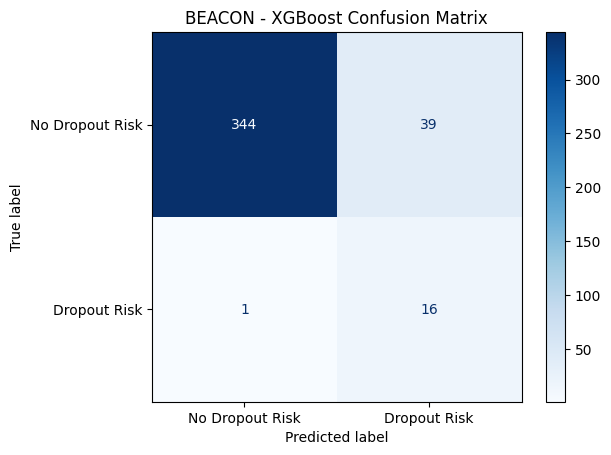

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict using the test dataset
y_pred = model.predict(X_test)

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

# Display detailed report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Dropout Risk", "Dropout Risk"],
    zero_division=0
))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Dropout Risk", "Dropout Risk"]
).plot(cmap="Blues")

plt.title("BEACON - XGBoost Confusion Matrix")
plt.show()

In [ ]:
import pandas as pd

importances = pd.Series(
    model.feature_importances_, index=X_train.columns
).sort_values(ascending=False)
print(importances.head(10))

CGPA               0.563890
Attendance_Rate    0.328940
Assignment_Avg     0.033533
Internal_Mark      0.025165
Age                0.024952
Backlogs           0.023520
dtype: float32


In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import pandas as pd

# Select features for BEACON
feature_columns = [
    "CGPA",
    "Attendance_Rate",
    "Assignment_Avg",
    "Internal_Mark",
    "Backlogs"
]

X = df[feature_columns]
y = df["Dropout_Risk"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Handle class imbalance
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

# Train the model
model = XGBClassifier(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.05,
    min_child_weight=5,
    reg_alpha=1.0,
    reg_lambda=5.0,
    scale_pos_weight=negative_count / positive_count,
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)

print("BEACON model training completed!")

BEACON model training completed!


Feature Importance:
CGPA               0.653342
Attendance_Rate    0.282383
Internal_Mark      0.023041
Backlogs           0.020907
Assignment_Avg     0.020327
dtype: float32


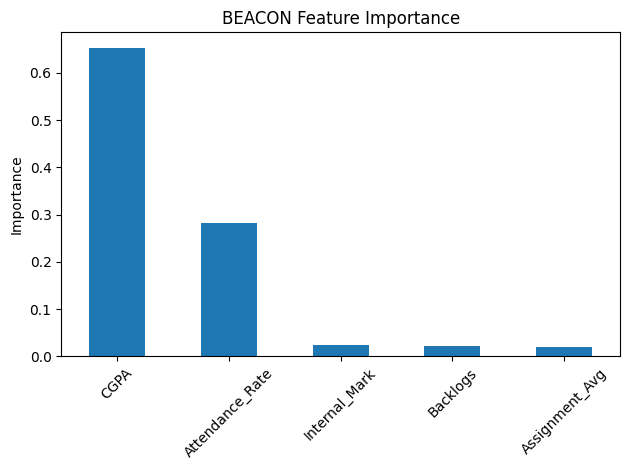

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(importance)

importance.plot(kind="bar")
plt.title("BEACON Feature Importance")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9
Precision: 0.2909090909090909
Recall: 0.9411764705882353
F1 Score: 0.4444444444444444

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95       383
           1       0.29      0.94      0.44        17

    accuracy                           0.90       400
   macro avg       0.64      0.92      0.69       400
weighted avg       0.97      0.90      0.92       400

Confusion Matrix:
[[344  39]
 [  1  16]]


Feature Importance:
CGPA               0.653342
Attendance_Rate    0.282383
Internal_Mark      0.023041
Backlogs           0.020907
Assignment_Avg     0.020327
dtype: float32


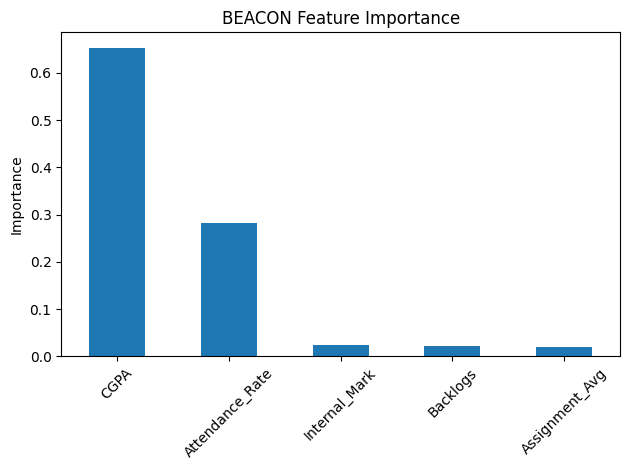

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(importance)

importance.plot(kind="bar")
plt.title("BEACON Feature Importance")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

===== BEACON MODEL EVALUATION =====
Accuracy  : 90.00%
Precision : 29.09%
Recall    : 94.12%
F1 Score  : 44.44%

===== CLASSIFICATION REPORT =====
                 precision    recall  f1-score   support

No Dropout Risk       1.00      0.90      0.95       383
   Dropout Risk       0.29      0.94      0.44        17

       accuracy                           0.90       400
      macro avg       0.64      0.92      0.69       400
   weighted avg       0.97      0.90      0.92       400

===== CONFUSION MATRIX =====
[[344  39]
 [  1  16]]


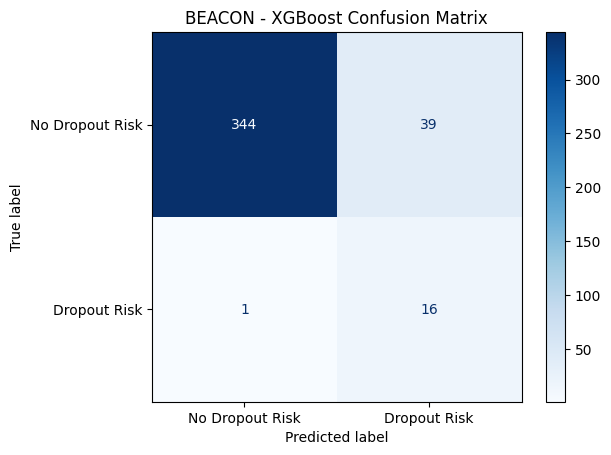

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Predict test data
y_pred = model.predict(X_test)

# 2. Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# 3. Display results
print("===== BEACON MODEL EVALUATION =====")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

# 4. Detailed report for both classes
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No Dropout Risk", "Dropout Risk"],
    zero_division=0
))

# 5. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("===== CONFUSION MATRIX =====")
print(cm)

# 6. Plot confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Dropout Risk", "Dropout Risk"]
)
display.plot(cmap="Blues", values_format="d")
plt.title("BEACON - XGBoost Confusion Matrix")
plt.show()


In [ ]:
import pandas as pd

importances = pd.Series(
    model.feature_importances_, index=X_train.columns
).sort_values(ascending=False)
print(importances.head(10))

CGPA               0.653342
Attendance_Rate    0.282383
Internal_Mark      0.023041
Backlogs           0.020907
Assignment_Avg     0.020327
dtype: float32
